**Disclaimer:** `Parts of this notebook might have been created with the assistance of large language models`                                 

# Machine Learning Project: E-Commerce Return Rate Prediction

## 1. Business Context and Problem Statement
In the e-commerce industry, managing product returns is a major financial and logistical challenge. Returns generate significant costs (shipping fees, repackaging, stock depreciation, customer service) and directly impact a company's net margin. 

The goal of this project is to develop a Machine Learning pipeline capable of accurately predicting the return rate of products (`return_rate_pct`). Anticipating these rates allows businesses to optimize inventory management, adjust pricing strategies, or target specific product pages for improvement in order to minimize losses.

## 2. Plan of Attack and Strategy
To achieve this goal in a rigorous and reproducible manner, our approach is structured as follows:
1. **Data Loading and Exploratory Data Analysis (EDA):** Initial data handling, checking for missing or anomalous values, and visualizing distributions (including skewness) and correlations to understand the underlying data dynamics.
2. **Establishing a Baseline:** Training a simple naïve model to set a minimum performance threshold that our complex models must beat.
3. **Trying different models:** We will first test several machine learning models on the entire dataset to evaluate their global performance. Then, guided by the bimodal distribution observed in our target variable, we will create a threshold to split the data into two distinct regimes. We will then test and apply different, specialized models to each specific subset of the data.
4. **Validation and Optimization (Nested Cross-Validation):** Using nested cross-validation to optimize hyperparameters without data leakage, ensuring robust and unbiased results.
5. **Error Analysis and Conclusion:** Studying the residuals to identify the model's limitations and proposing operational next steps.

## Imports and setup

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import warnings
import xgboost as xgb
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings('ignore')

np.random.seed(42)
sns.set_theme()

# 1. Data Loading and Exploratory Data Analysis (EDA):

We start by loading the entries from the given datasets.

In [ ]:
train = pd.read_csv("data/track_k_ecommerce_returns_train.csv")
test = pd.read_csv("data/track_k_ecommerce_returns_test.csv")

Our dataset contains the following columns:

| Feature | Type | Range | Description |
|---|---|---|---|
| `price_eur` | float | 8–280 | Selling price in EUR. |
| `discount_pct` | float | 0–60 | Discount percentage. |
| `size_variants_count` | int | 1–12 | Number of available size variants. |
| `shipping_days` | float | 1–10 | Average shipping lead time. |
| `product_rating` | float | 2.2–5.0 | Product rating score. |
| `review_volume` | int | 5–600 | Number of reviews. |
| `image_quality_score` | float | 0–10 | Image quality score. |
| `description_quality_score` | float | 0–10 | Description quality score. |
| `size_mismatch_reports` | int | 0–35 | Historical mismatch report count. |
| `category_complexity_index` | float | 0–10 | Category complexity index. |
| `holiday_campaign_flag` | binary | 0/1 | Whether campaign runs in holiday period. |
| `packaging_color_code` | int | 1–6 | Packaging color category code. |
| **`return_rate_pct`** | float | 0–90 | **Target: expected return percentage.** |

We want to estimate `return_rate_pct` based on the 12 features. 

Before starting our analysis, let us first check for missing values.

In [ ]:
print("Are there missing values?")
bool(train.isnull().values.any())

Are there missing values?


False

## 1.1 Heatmap

Before analyzing the distributions, it is useful to get initial insight into the data by plotting a heatmap of the correlation matrix:

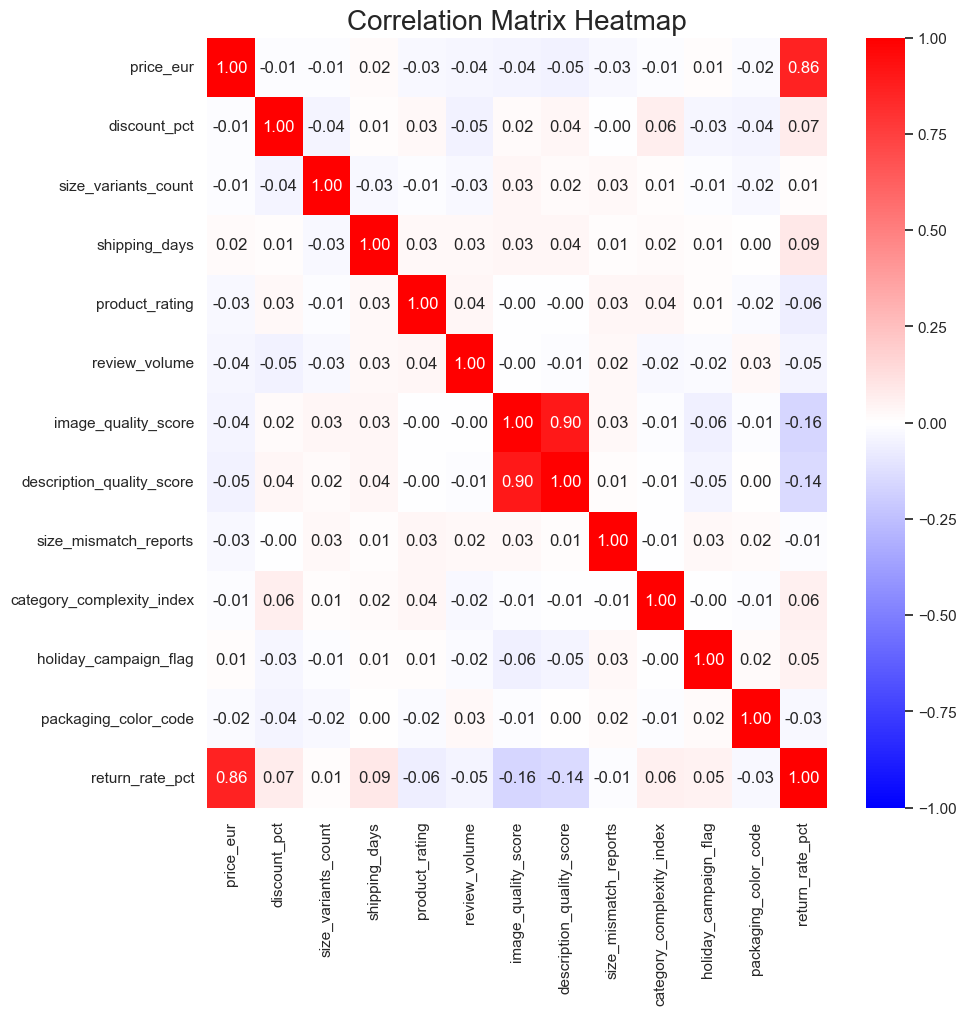

In [ ]:
fig = plt.figure(figsize=(10,10))
plt.title("Correlation Matrix Heatmap", fontsize=20)
sns.heatmap(train.corr(), cmap="bwr", vmin ='-1', annot=True, fmt=".2f")
plt.show()

After an initial inspection of the heatmap, we can already observe:
- `price_eur` is **highly positively correlated** (0.86) with our target (more expensive products seem to be more likely to be returned)
- `image_quality_score` and `description_quality_score` are **negatively correlated** (-0.16, -0.14) with our target (products with lower quality presentation are more likely to be returned); at the same time, they are **highly positively correlated** with each other (0.9)
- excluding `image_quality_score` and `description_quality_score`, there doesn't seem to exist strong multicollinearity between the features themselves
- `discount_pct`, `shopping_days`, `cateogry_complexity_index`, `holiday_campaign_flag`, `review_volume`, `product_raiting` are not very highly correlated ($0.05 < |\cdot| < 0.09$) with the target, but as their names suggest, could still be reasonably relevant for the prediction (for example, we expect product raitings to somewhat affect the return rate)
- `size_variants_count`, `size_mismatch_reports` and `packaging_color_code` only show little correlation with the target

## 1.2 Distributions of features and target

## Target distribution is bimodal

First, it is important to analyze the distribution of the target (`return_rate_pct`):

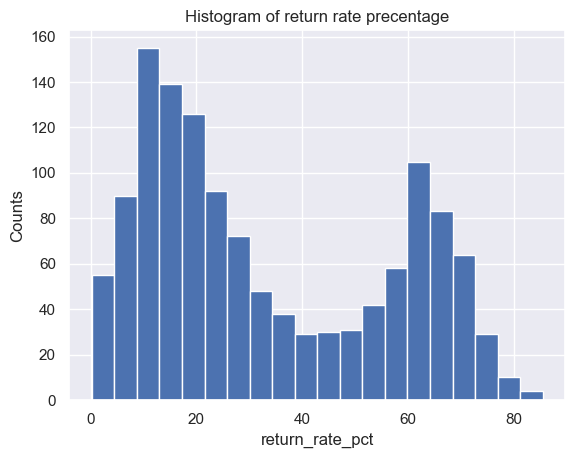

In [ ]:
fig = plt.figure()
plt.title("Histogram of return rate precentage")
plt.ylabel("Counts")
plt.xlabel("return_rate_pct")
plt.hist(train['return_rate_pct'], bins=20)
plt.show()

###  Interpretation: Target Variable Distribution Analysis

The histogram above highlights a fundamental characteristic of our target variable (`return_rate_pct`): **its distribution is clearly bimodal**. 

Specifically, we observe one peak around the **10-15%** return rate and another distinct peak around the **60-65%** return rate. Our dataset lacks entries in the middle ground, indicating that most campaigns (or products) experience either a reasonably low or a reasonably high return rate. Interestingly, the respective rates appear to be approximately "normally distributed" around their corresponding peaks.

**Impact and Modeling Intuition (Spoiler):**
This particular shape could be problematic for obtaining accurate predictions using standard methods. It strongly indicates that our dataset does not describe a single homogeneous population, but rather two distinct sub-populations governed by different behaviors (e.g., different price ranges or product categories). 

A single global model trained on the entire dataset would likely converge towards the global mean (the empty middle ground), leading to highly inaccurate predictions for both groups. 

## The bimodal distribution of the target reflected in relation to the features

When attempting to plot the features (except for `price_eur`) against `return_rate_pct` we observe a similar bimodal pattern.

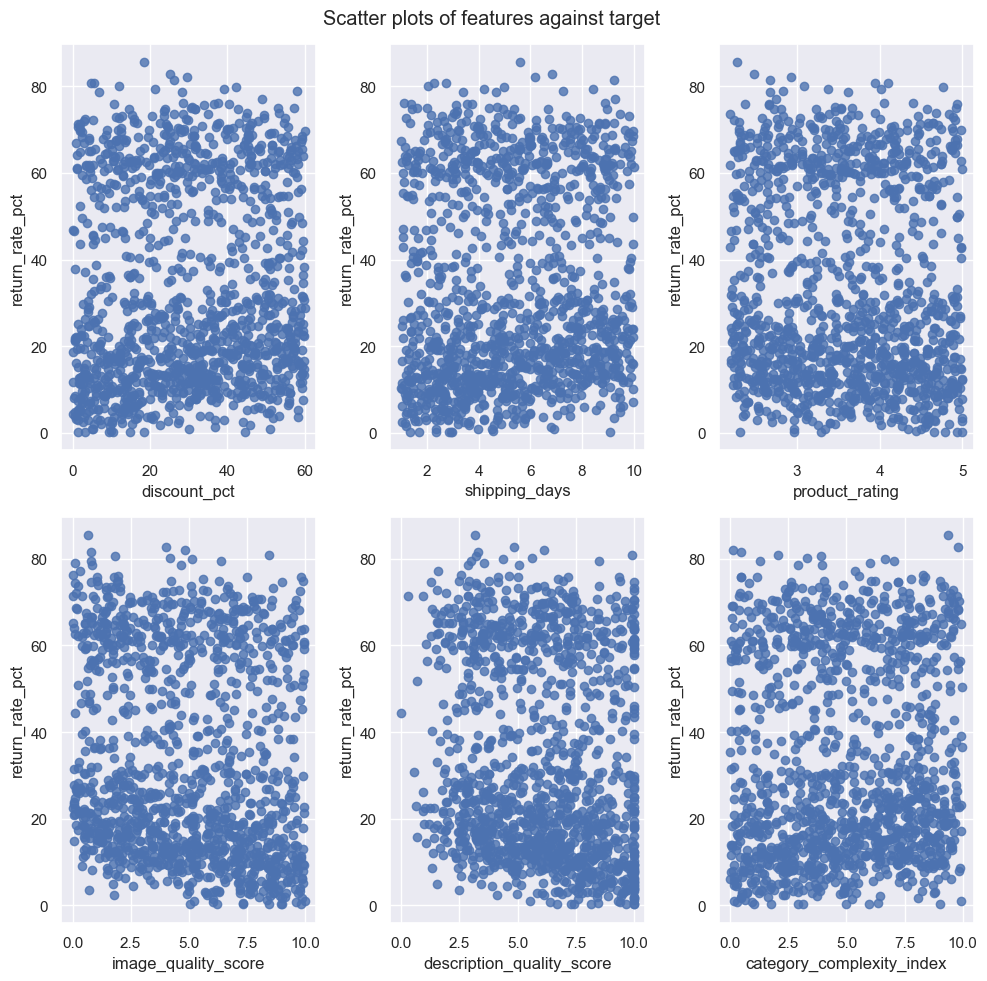

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10,10))
plt.suptitle("Scatter plots of features against target")

# Plot each of the selected features against the target
features = ['discount_pct', 'shipping_days', 'product_rating', 'image_quality_score', 'description_quality_score', 'category_complexity_index']
for i, ax in enumerate(axes.flat):
    ax.scatter(train[features[i]], train['return_rate_pct'], alpha=0.8)
    ax.set_xlabel(features[i])
    ax.set_ylabel('return_rate_pct')

plt.tight_layout()
plt.show()

- The middle region in each feature vs target scatterplot is caused by the existence of the two modes of the distribution of `return_rate_pct`. 
- Beyond this, the relationships between those features and the target are not perfectly clear; this is expected given the low correlation coefficients between most of the features and target. 

## Uniform distribution of features

Here is an overview of the distribution of the features:

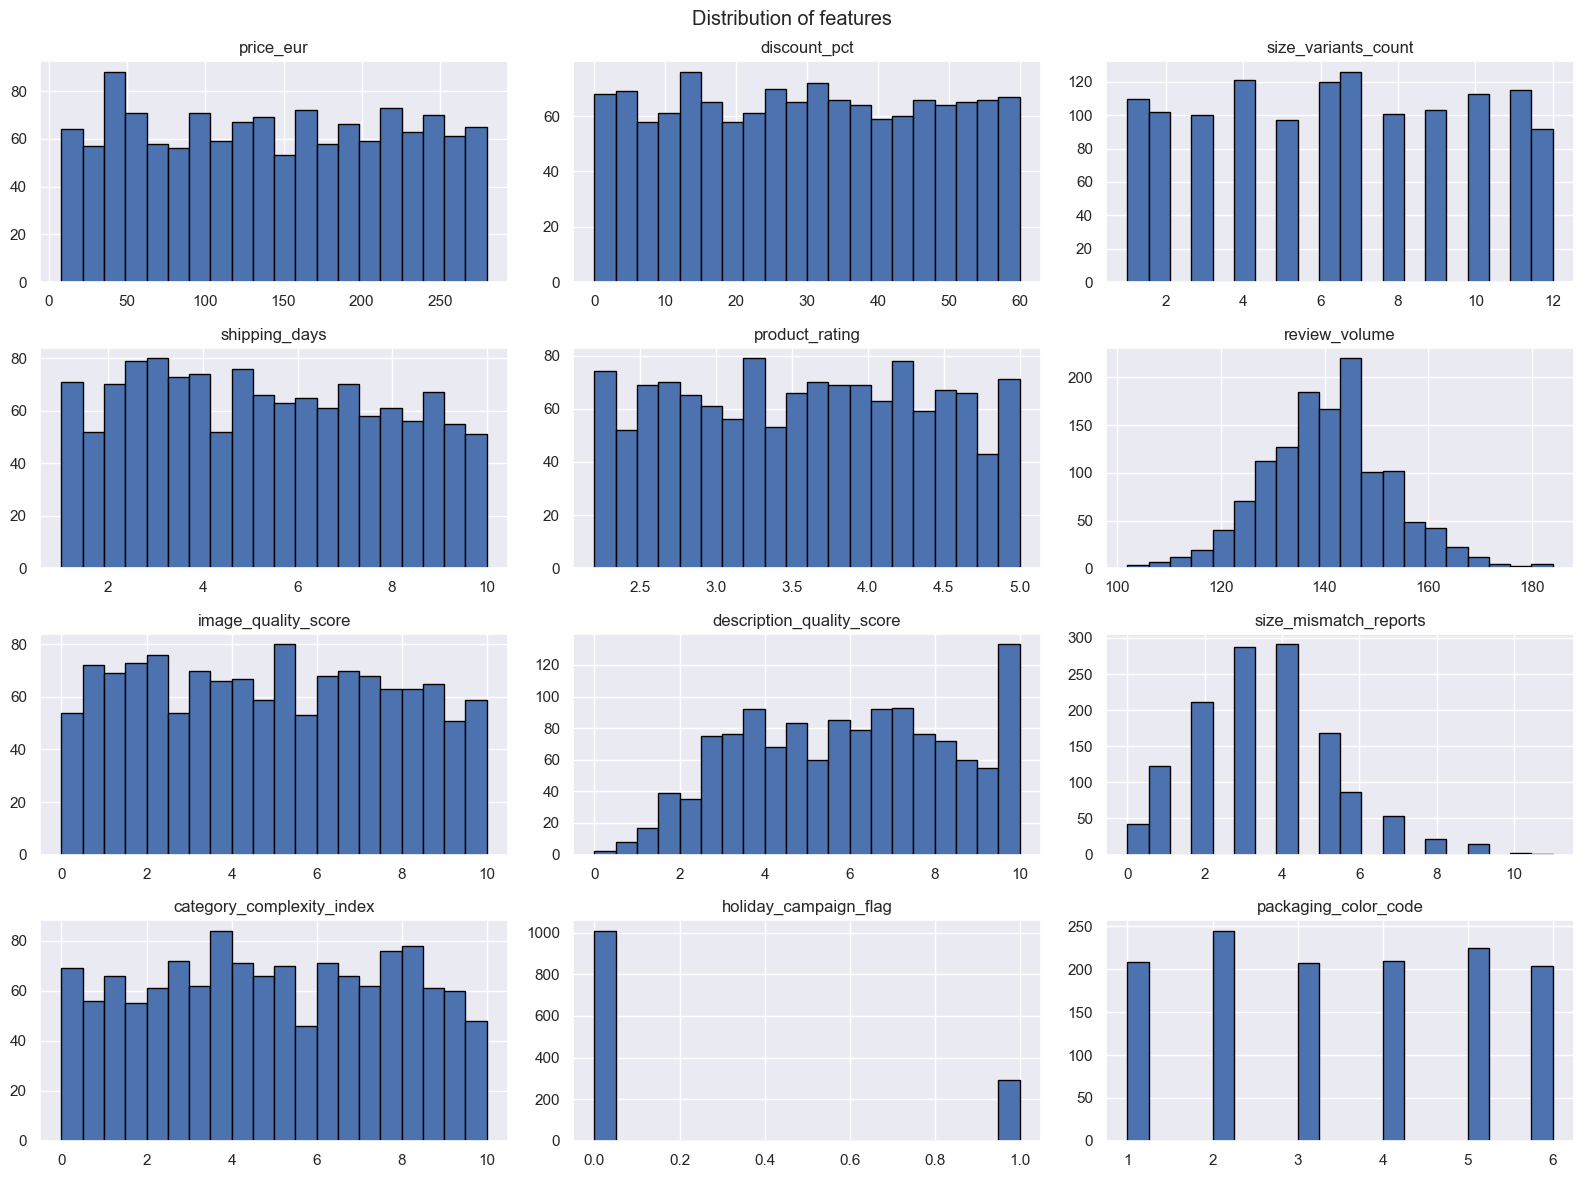

In [ ]:
train.drop(columns=['return_rate_pct']).hist(figsize=(16, 12), bins=20, edgecolor='black')
plt.suptitle("Distribution of features")
plt.tight_layout()
plt.show()

Most of the continuous data seems perfectly uniformely distributed. <br>
Nothing interesting seems to happen here.

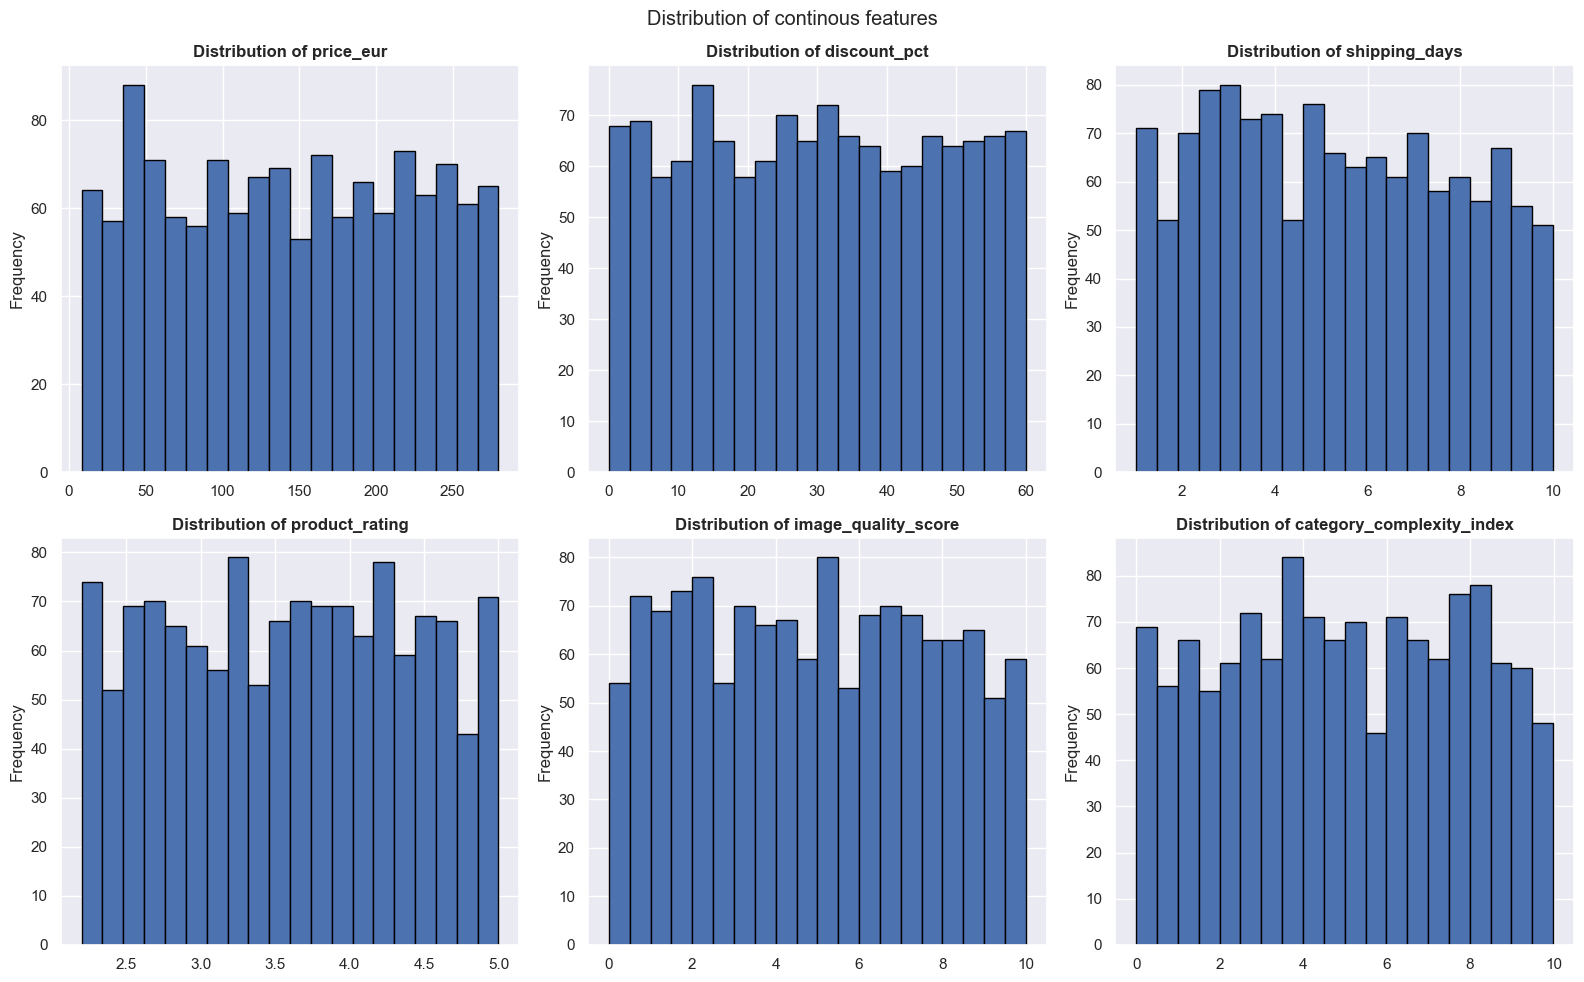

In [ ]:
uniform_cols = [
    'price_eur', 
    'discount_pct', 
    'shipping_days', 
    'product_rating',
    'image_quality_score', 
    'category_complexity_index'
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(uniform_cols):
    axes[i].hist(train[col], bins=20, edgecolor='black')
    
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Frequency')

plt.suptitle("Distribution of continous features")
plt.tight_layout()
plt.show()

Two of the discrete features are uniform as well.<br>
Once again, nothing interesting happens here. 

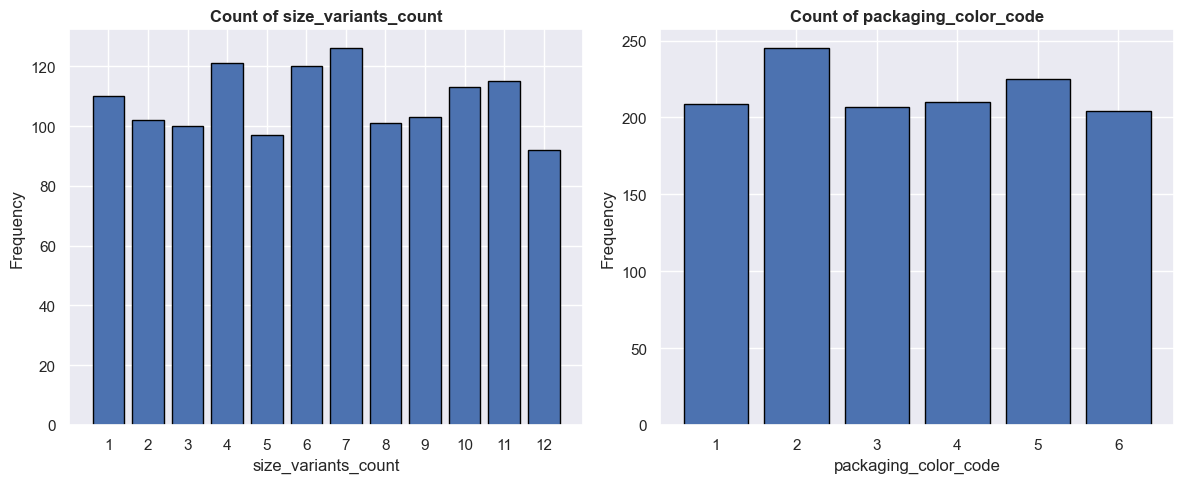

In [ ]:
discrete_uniform_cols = [
    'size_variants_count', 
    'packaging_color_code'
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

for i, col in enumerate(discrete_uniform_cols):
    counts = train[col].value_counts().sort_index()
    

    axes[i].bar(counts.index, counts.values, edgecolor='black')
    
    axes[i].set_title(f'Count of {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Frequency')
    axes[i].set_xlabel(col)
    
    axes[i].set_xticks(counts.index)

plt.tight_layout()
plt.show()

We have 8 out of 12 features that are uniformly distributed. 

The distribution of the description quality score is divided in three parts. 
- We can notice that the left tail is kind of missing between 0 and 2; Very few items have bad/garbage description.
- In the middle, it seems more uniformly distributed.
- On the far right side, we can see a peak of frequency.

Since it is the description quality score, we can suppose that most people won't even buy the low quality ones, hence the missing left tail. The middle is uniformly distributed so there's no much to say, but we can assume that the peak on the far right means that people are inclined to buy the items with excellent quality score.

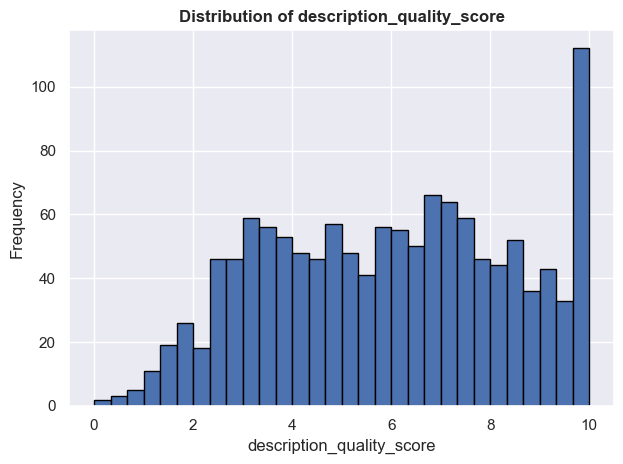

In [ ]:
plt.hist(train['description_quality_score'], bins=30, edgecolor='black')

plt.title('Distribution of description_quality_score', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('description_quality_score')

plt.tight_layout()
plt.show()

The review volume seems normally distributed. Most of the items have around 140 review. It is also quite rare for the review to be too low or too high. 

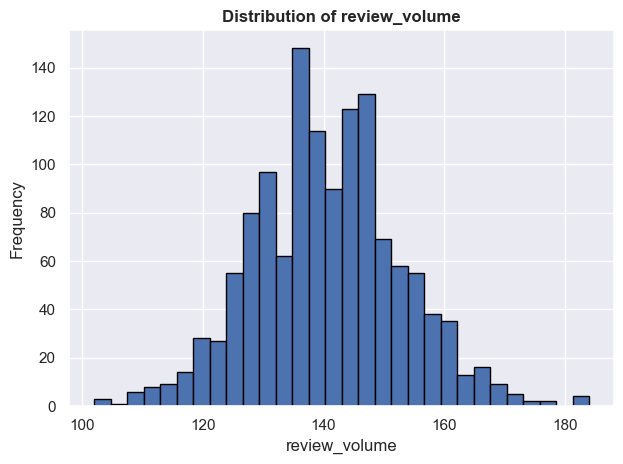

In [ ]:
plt.hist(train['review_volume'], bins=30, edgecolor='black')

plt.title('Distribution of review_volume', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('review_volume')
plt.tight_layout()
plt.show()

The distribution of size mismatch reports looks like a Poisson distribution. Since the distribution is clearly right skewed, does not look like a normal, we can interpret it as a rare event. 

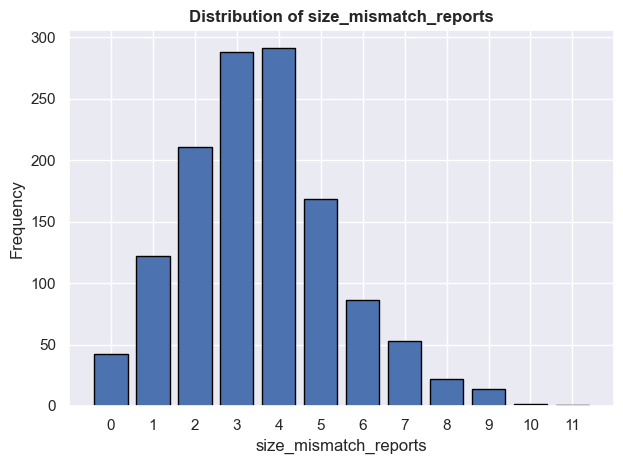

In [ ]:
counts = train['size_mismatch_reports'].value_counts().sort_index()

plt.bar(counts.index, counts.values, edgecolor='black')

plt.title('Distribution of size_mismatch_reports', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('size_mismatch_reports')

plt.xticks(counts.index)

plt.tight_layout()
plt.show()

`holiday_campaign_flag` has an asymmetric distribution, but since the correlation with the target is low (0.05), we will ignore this for now (we will see that it is not at all a crucial feature for making predictions).

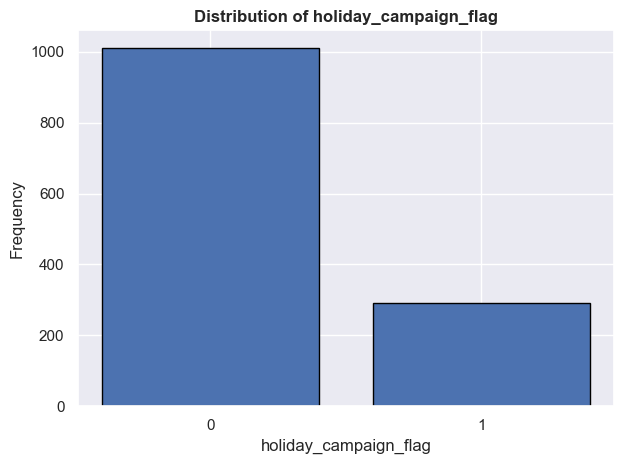

In [ ]:
counts = train['holiday_campaign_flag'].value_counts().sort_index()

plt.bar(counts.index, counts.values, edgecolor='black')

plt.title('Distribution of holiday_campaign_flag', fontsize=12, fontweight='bold')
plt.ylabel('Frequency')
plt.xlabel('holiday_campaign_flag')

plt.xticks(counts.index)

plt.tight_layout()
plt.show()

### `price_eur` against the target 

Perhaps the most important predictor for our target is the `price_eur`, with a huge correlation coefficient of 0.86.

Let us vizualise their relationship:

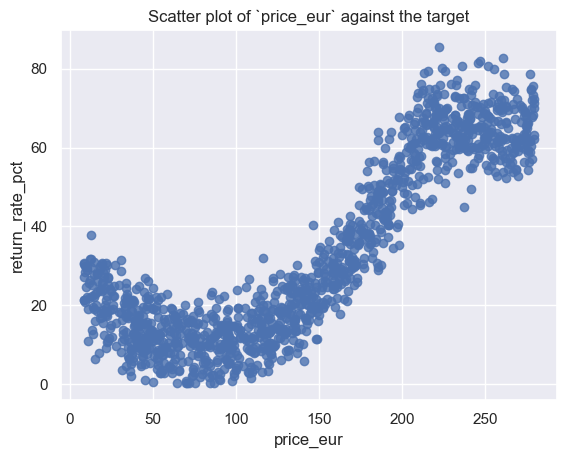

In [ ]:
fig = plt.figure()
plt.title("Scatter plot of `price_eur` against the target")
plt.ylabel("return_rate_pct")
plt.xlabel("price_eur")
plt.scatter(train['price_eur'], train['return_rate_pct'], alpha=0.8)
plt.show()

The pattern resembles a polynomial of degree greater than 2 (we will look more into the exact degree later). This is promising for our model, as until this point, it is the clearest link between a feature and the target.

## The linear relationship between `image_quality_score` and `description_quality_score`

Pearson Correlation Coefficient: 0.90


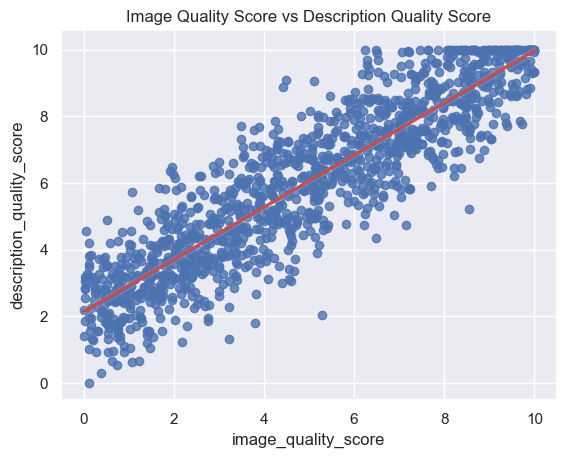

In [ ]:
# Calculate the Pearson correlation coefficient
corr_coef = train['image_quality_score'].corr(train['description_quality_score'])
print(f"Pearson Correlation Coefficient: {corr_coef:.2f}")

# Plot the relationship
fig = plt.figure()
plt.title("Image Quality Score vs Description Quality Score")
sns.regplot(data=train, x='image_quality_score', y='description_quality_score', line_kws=dict(color="r"))
plt.show()

There is clearly a linear relationship between the `image_quality_score` and `description_quality_score` features, with a **Pearson Correlation Coefficient** of **0.90**.

### Outliers and ranges

Let us also take a look into the ranges and outliers using boxplots. We separated them into multiple plots because of the difference in range between features.

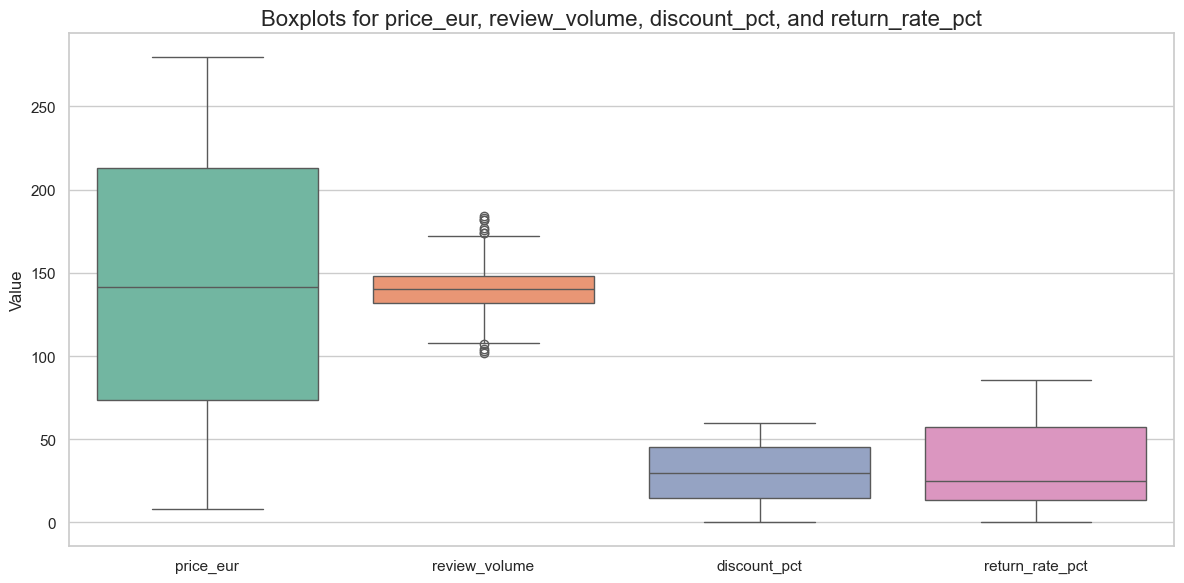

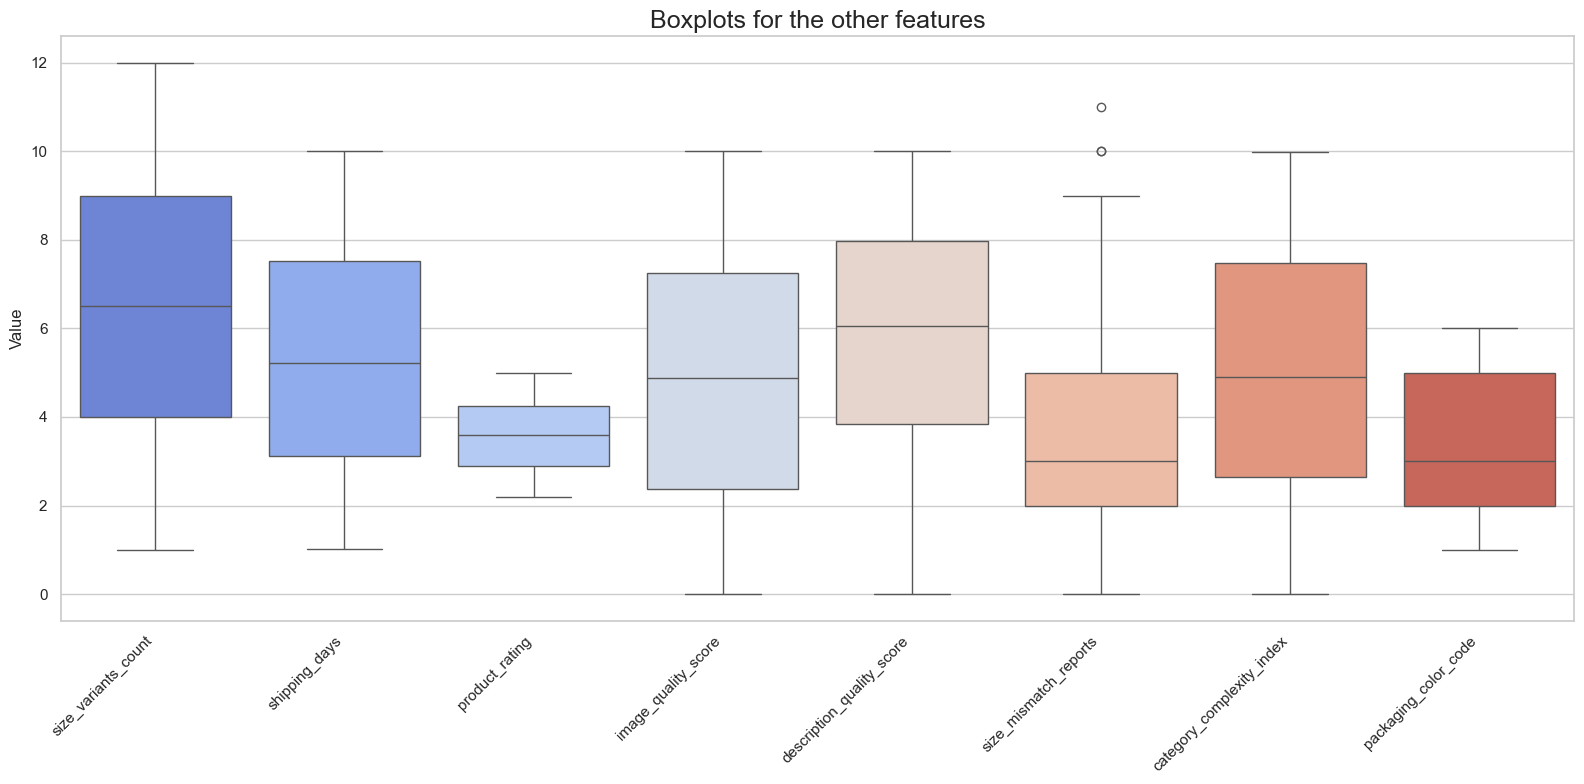

In [ ]:
selected_cols = ['price_eur', 'review_volume', 'discount_pct', 'return_rate_pct']
exclude_cols = selected_cols + ['holiday_campaign_flag']
other_cols = [col for col in train.columns if col not in exclude_cols]

sns.set_style('whitegrid')
plt.figure(figsize=(12, 6))
train_selected_melted = train[selected_cols].melt(var_name='Feature', value_name='Value')
sns.boxplot(x='Feature', y='Value', data=train_selected_melted, palette='Set2')
plt.title('Boxplots for price_eur, review_volume, discount_pct, and return_rate_pct', fontsize=16)
plt.xlabel("")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 8))
train_other_melted = train[other_cols].melt(var_name='Feature', value_name='Value')
sns.boxplot(x='Feature', y='Value', data=train_other_melted, palette='coolwarm')
plt.title('Boxplots for the other features', fontsize=18)
plt.xlabel("")
plt.ylabel("Value")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In general, there is a limited number of outliers. The only problematic outliers are perhaps in review_volume, but:

- We have already seen that it has little correlation with the target (-0.05)
- As we move further, we will see that review_volume is not extremely relevant for predicting the target, so it is okay to move on for now, especially since there are not too many outliers.

### Setup for training models

In [ ]:
X_train = train.drop(columns=['return_rate_pct'])
y_train = train['return_rate_pct']
X_test = test.drop(columns=['return_rate_pct'])
y_test = test['return_rate_pct']

# 2. Establishing the baseline: the naive approach (mean predictor)

In [ ]:
def quick_test_model(model, X_train, y_train, X_test, y_test, return_model=False):
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)


    print(f"Train MSE: {mean_squared_error(y_pred_train, y_train)}")
    print(f"Test MSE: {mean_squared_error(y_pred_test, y_test):.2f}")

    return model

   
from sklearn.dummy import DummyRegressor
baseline_model = quick_test_model(DummyRegressor(strategy='mean'), X_train, y_train, X_test, y_test)

Train MSE: 528.876580666213
Test MSE: 544.71


**Baseline Results:** We selected the global mean of the target variable as our naive baseline model. As expected, this simplistic approach performs poorly, yielding a **Mean Squared Error (MSE) of 544.71**. 

**Next Steps:** This high error rate establishes our benchmark. Our primary objective moving forward is to iteratively train and tune more sophisticated machine learning models to capture the underlying patterns in the campaign data and progressively drive this MSE down.

# 3. Trying different models

## 3.1 Linear Regression

In [ ]:
# Helper function for plotting residuals

def plot_residual_summaries(model, y_pred_train, y_pred_test):

    residuals_train = y_train - y_pred_train
    residuals_test = y_test - y_pred_test

    # Create comprehensive residual diagnostics
    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    # Plot 1: Residuals vs Fitted (most important!)
    axs[0, 0].scatter(y_pred_train, residuals_train, alpha=0.6, s=60)
    axs[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axs[0, 0].set_xlabel('Fitted values (ŷ)', fontsize=11)
    axs[0, 0].set_ylabel('Residuals (y - ŷ)', fontsize=11)
    axs[0, 0].set_title('Residuals vs fitted', fontsize=11, fontweight='bold')
    axs[0, 0].grid(alpha=0.3)

    # Plot 2: Histogram
    axs[0, 1].hist(residuals_train, bins=12, alpha=0.7, edgecolor='black', color='orange')
    axs[0, 1].set_xlabel('Residuals', fontsize=11)
    axs[0, 1].set_ylabel('Frequency', fontsize=11)
    axs[0, 1].set_title('Distribution of Residuals', fontsize=11, fontweight='bold')
    axs[0, 1].grid(alpha=0.3, axis='y')

    # Plot 3: QQ plot
    axs[1, 0].set_title('QQ Plot', fontsize=11, fontweight='bold')
    fig = sm.qqplot(residuals_train, stats.norm, fit=True, line='q', ax=axs[1, 0])


    # Plot 4: Residuals over observation index
    axs[1, 1].plot(residuals_train, 'o-', alpha=0.6, linewidth=1, markersize=5)
    axs[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axs[1, 1].set_xlabel('Observation Index', fontsize=11)
    axs[1, 1].set_ylabel('Residual', fontsize=11)
    axs[1, 1].set_title('Residuals in Order', fontsize=11, fontweight='bold')
    axs[1, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\nComparison of Training vs Test Residuals:")
    print(f"Training residuals mean: {residuals_train.mean():.6f}, std: {residuals_train.std():.4f}")
    print(f"Test residuals mean: {residuals_test.mean():.6f}, std: {residuals_test.std():.4f}")

Let us begin with a naive linear regression applied to the training data:

In [ ]:
linreg = quick_test_model(LinearRegression(), X_train, y_train, X_test, y_test)

Train MSE: 118.68086063613538
Test MSE: 125.98


We already observe a massive improvement over our baseline model in terms of MSE. To dive deeper, it is necessary to analyze the residual plots. \
Let us analyze the distribution of the residuals and model assumptions:

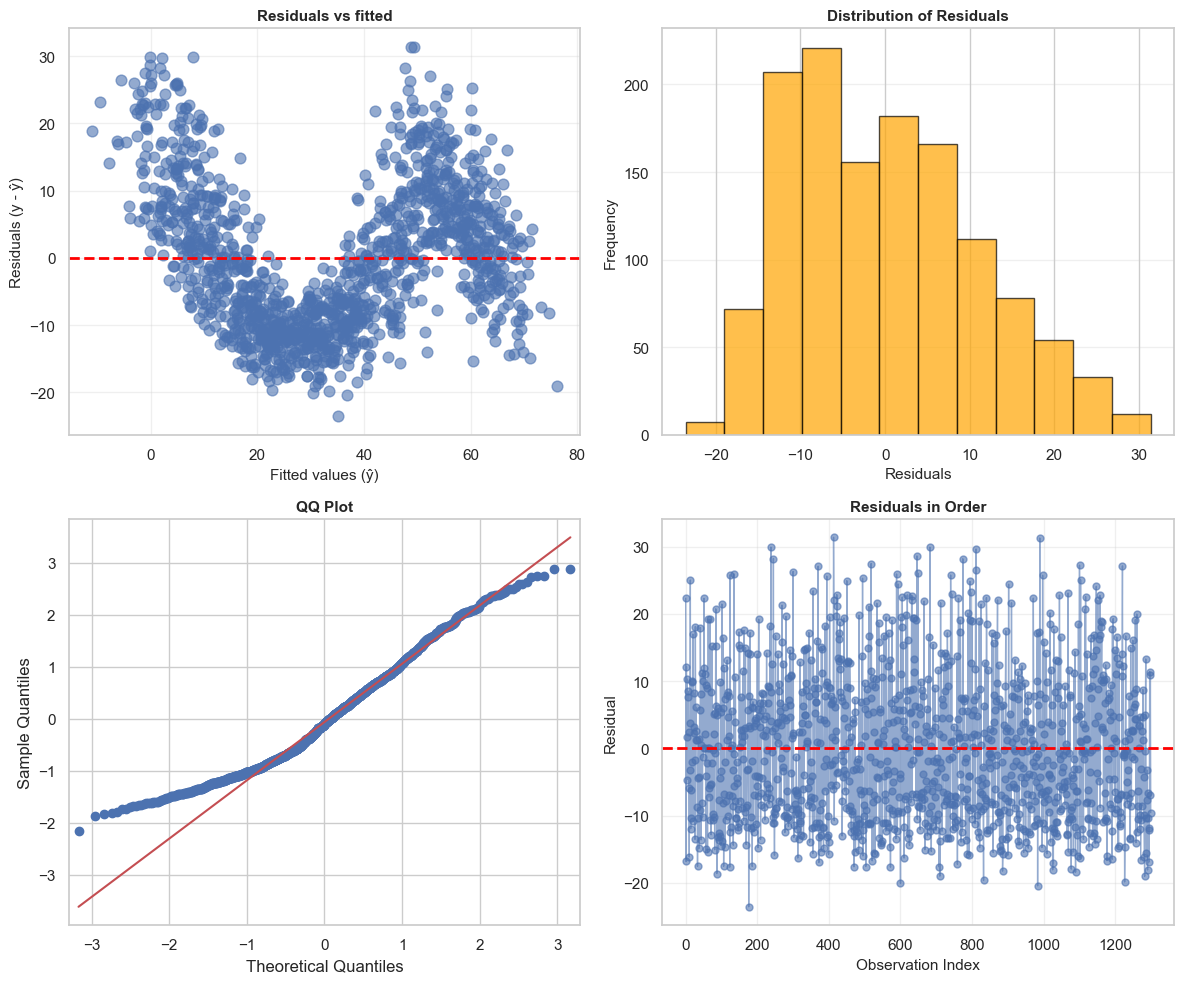


Comparison of Training vs Test Residuals:
Training residuals mean: 0.000000, std: 10.8983
Test residuals mean: -0.630997, std: 11.2223


In [ ]:
y_pred_train = linreg.predict(X_train)
y_pred_test = linreg.predict(X_test)
plot_residual_summaries(linreg, y_pred_train, y_pred_test)

It looks like the main issue to diagnose is that the relationship between the features and the target is not linear and the residuals are not normally distributed. The residuals vs fitted plot directs us towards attempting polynomial regression by including powers of `price_eur`, as suggested by the `price_eur` vs target scatterplot we discussed earlier.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

results = []
models = {}

for degree in range(2, 12):
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = np.hstack([
        poly.fit_transform(X_train[['price_eur']]),
        X_train.drop(columns='price_eur')
    ])

    X_test_poly = np.hstack([
        poly.transform(X_test[['price_eur']]),
        X_test.drop(columns='price_eur')
    ])

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred_test = model.predict(X_test_poly)
    y_pred_train = model.predict(X_train_poly)


    results.append({
        "degree": degree,
        "test_mse": mean_squared_error(y_test, y_pred_test),
        "train_mse": mean_squared_error(y_train, y_pred_train)
    })

    models[degree] = {
        "model": model,
        "X_train": X_train_poly,
        "X_test": X_test_poly
    }

print("The top 3 performing degrees for the feature price_eur:")
results_df = pd.DataFrame(results).sort_values("test_mse")
display(results_df.set_index("degree").head(3))

The top 3 performing degrees for the feature price_eur:


,test_mse,train_mse
degree,,
4,26.859892,27.762655
5,26.941445,27.681189
3,34.365833,33.130041


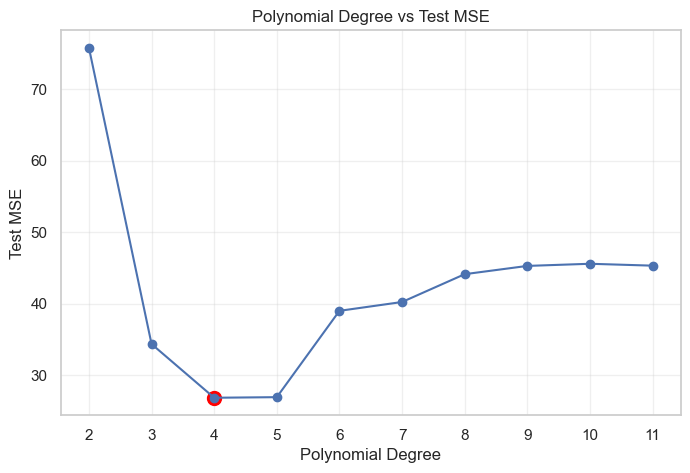

In [ ]:
import matplotlib.pyplot as plt

df = results_df.sort_values("degree").copy()
df["degree"] = df["degree"].astype(int)
df["test_mse"] = df["test_mse"].astype(float)

plt.figure(figsize=(8, 5))
plt.plot(df["degree"].to_numpy(), df["test_mse"].to_numpy(), marker="o")

best = df.loc[df["test_mse"].idxmin()]

plt.scatter(best["degree"], best["test_mse"], color="red", s=100)

plt.xlabel("Polynomial Degree")
plt.ylabel("Test MSE")
plt.title("Polynomial Degree vs Test MSE")
plt.xticks(df["degree"])
plt.grid(alpha=0.3)
plt.show()

Adding powers of `price_eur` improved the MSE to a promising value of around 26.85 when the degree of the polynomial transofrmation of price_eur is set to 4.

Let us redraw the residual plots when the best-performing degree of the polynomial (4) is chosen:

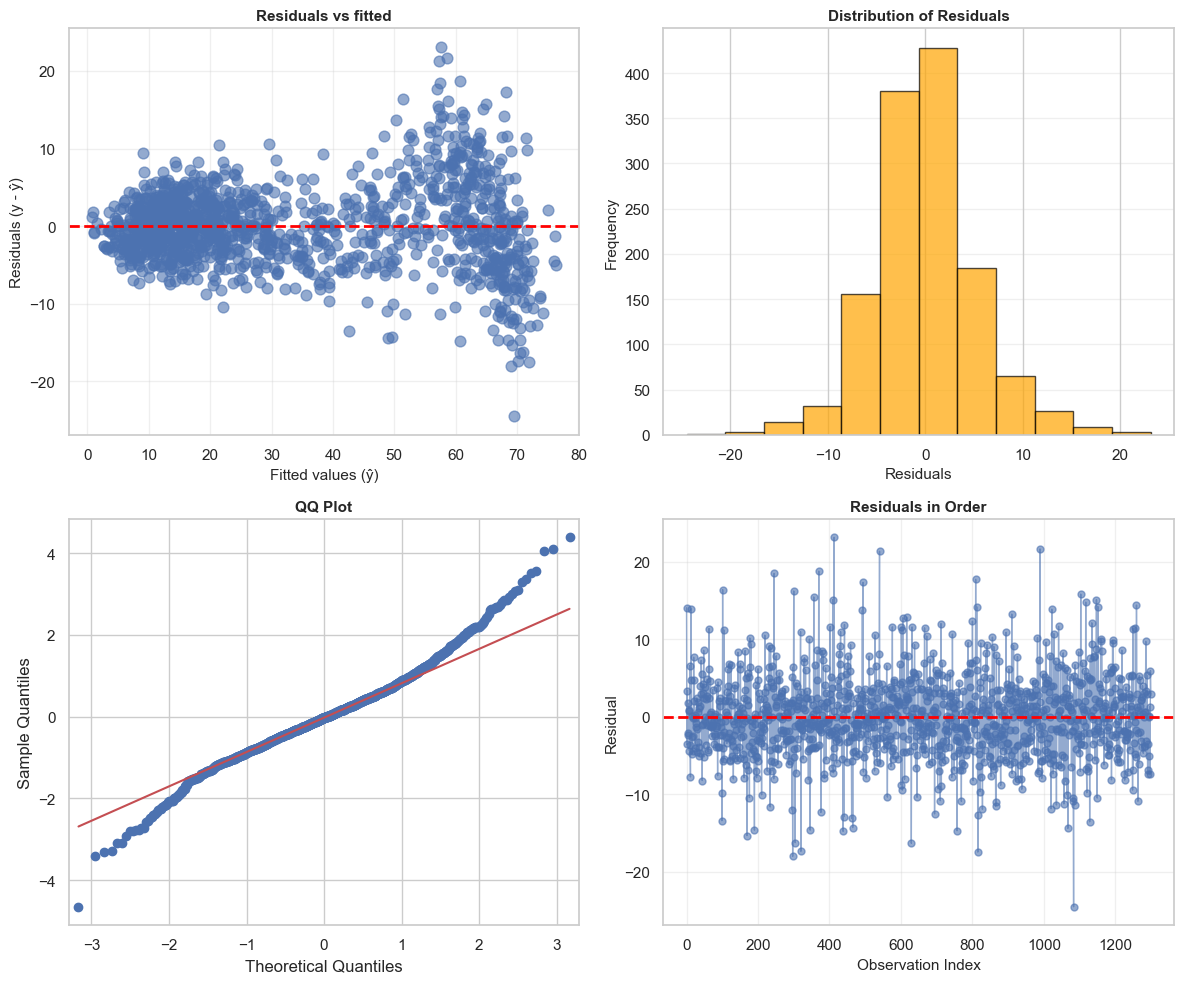


Comparison of Training vs Test Residuals:
Training residuals mean: 0.000000, std: 5.2711
Test residuals mean: -0.079320, std: 5.1895
Train MSE: 27.762655482767155
Test MSE: 26.86


In [ ]:
deg = 4  

best_model = models[deg]["model"]
X_train_poly = models[deg]["X_train"]
X_test_poly = models[deg]["X_test"]

y_pred_train = best_model.predict(X_train_poly)
y_pred_test = best_model.predict(X_test_poly)

plot_residual_summaries(linreg, y_pred_train, y_pred_test)

_ = quick_test_model(best_model, X_train_poly, y_train, X_test_poly, y_test)

The residuals more closely approximate a normal distribution now. Even though the model including powers of `price_eur` performs much better, there still seems to be greater variance in the second **mode** we noticed when analyzing the bimodal distribution of the target (in the high price range).  This indicates heteroscedasticity, so we will attempt a log transformation.

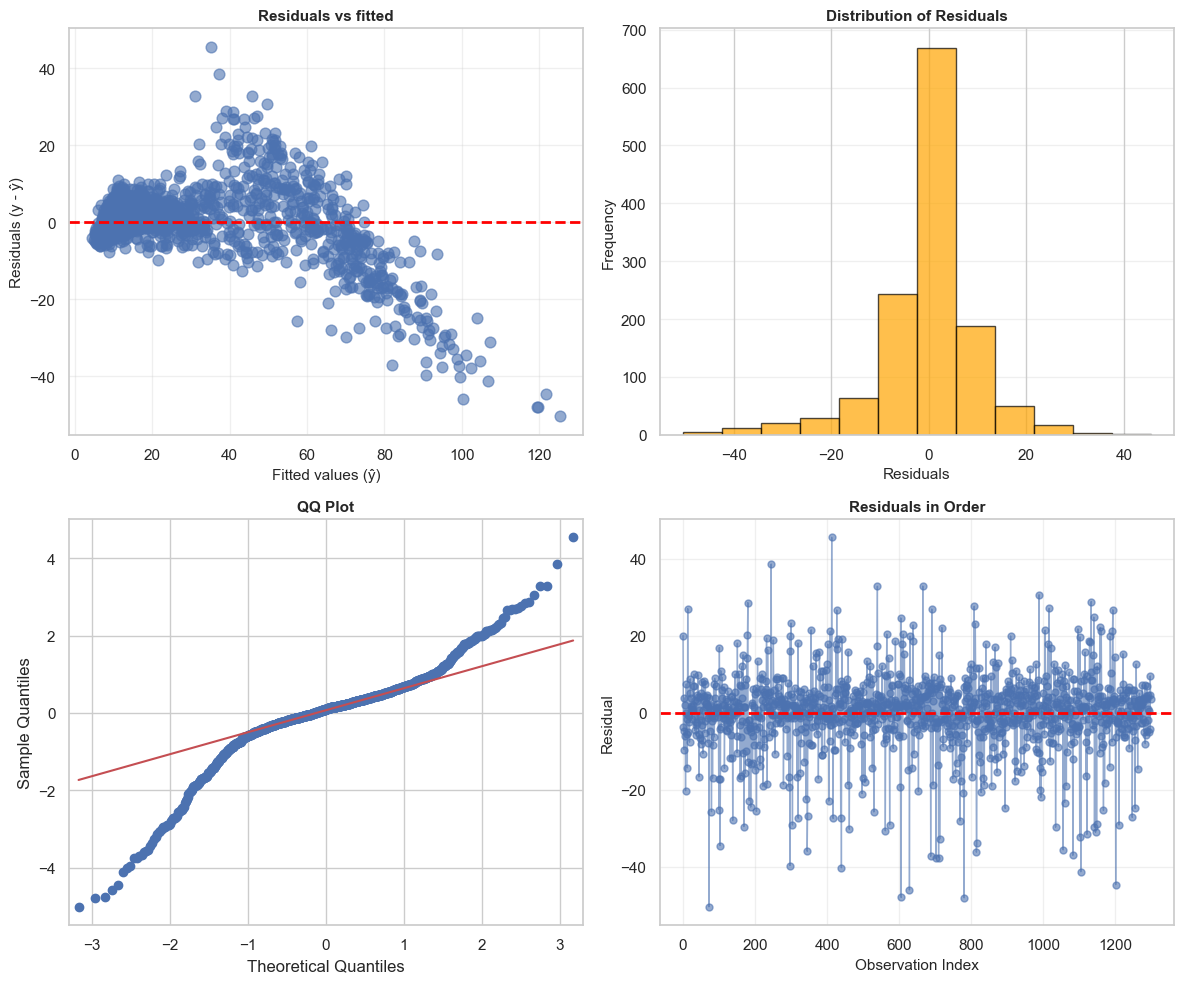


Comparison of Training vs Test Residuals:
Training residuals mean: -0.103649, std: 10.0497
Test residuals mean: 0.066493, std: 10.8383
Test MSE 117.1384819110485
Train MSE 100.92942010160218


In [ ]:
poly = PolynomialFeatures(degree=4, include_bias=False)

X_train_poly = np.hstack([
    poly.fit_transform(X_train[['price_eur']]),
    X_train.drop(columns='price_eur')
])

X_test_poly = np.hstack([
    poly.transform(X_test[['price_eur']]),
    X_test.drop(columns='price_eur')
])

y_train_log = np.log1p(y_train)

log_linreg = LinearRegression()
log_linreg.fit(X_train_poly, y_train_log)

y_pred_test_log = log_linreg.predict(X_test_poly)
y_pred_train_log = log_linreg.predict(X_train_poly)
y_pred_train = np.expm1(y_pred_train_log)
y_pred_test = np.expm1(y_pred_test_log)

plot_residual_summaries(log_linreg, y_pred_train, y_pred_test)

print("Test MSE", mean_squared_error(y_test, y_pred_test))
print("Train MSE", mean_squared_error(y_train, y_pred_train))

The log transformation generated a new situation: now the model is heavily overestimating in the high-price range. This truly indicates that the bimodality of the distribution of the target is tricky to handle without introducing more complex predictors. Before moving to different models, let us attempt polynomial features on the whole feature set (as opposed to just `price_eur`).

Train MSE: 4.051599574547909e-24
Test MSE: 1166.93


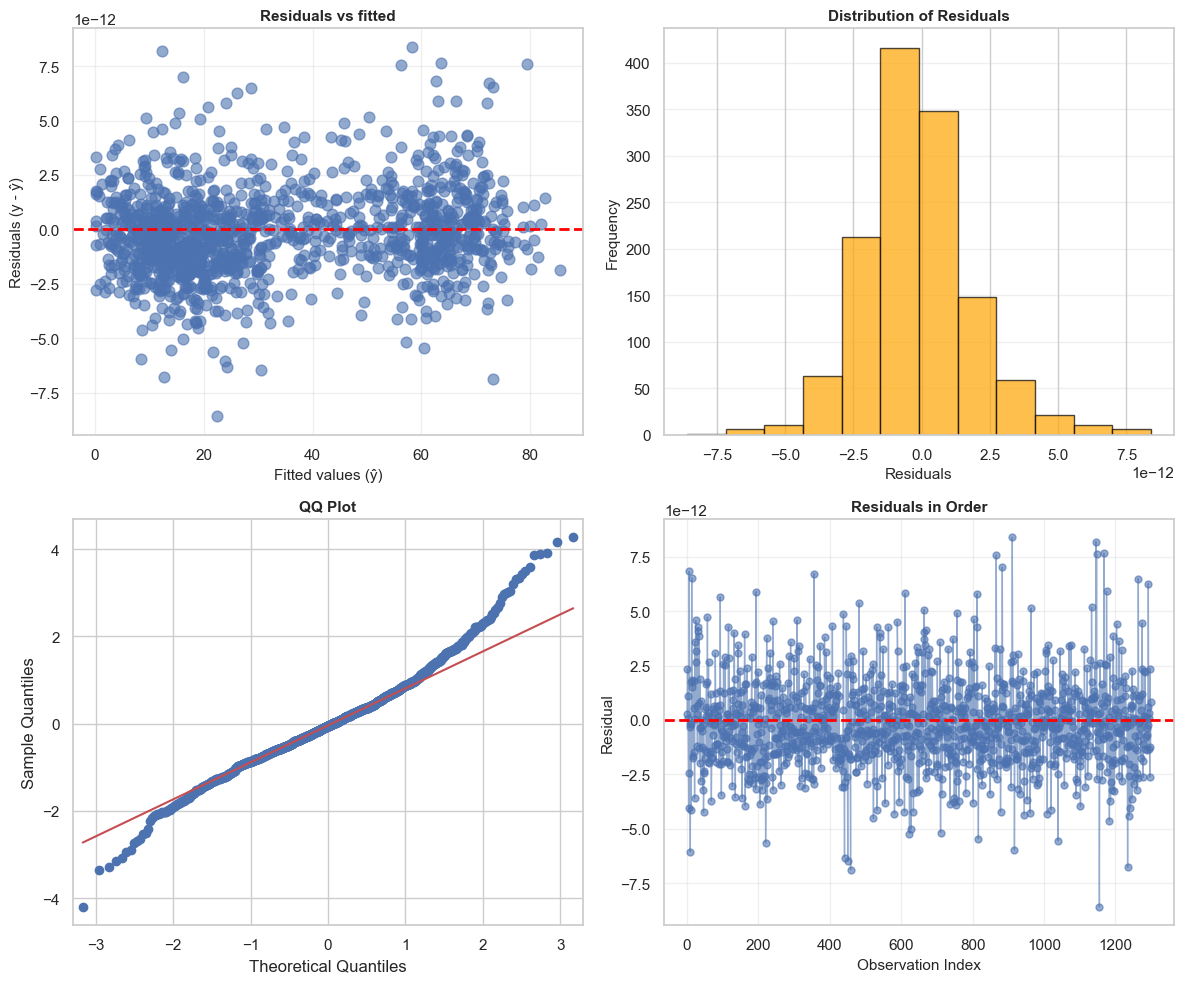


Comparison of Training vs Test Residuals:
Training residuals mean: -0.000000, std: 0.0000
Test residuals mean: 2.184780, std: 34.1392


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

interaction_model = Pipeline([
    ('poly', PolynomialFeatures(degree=4)), 
    ('scaler', StandardScaler()),
    ('linear', LinearRegression())
])

interaction_model = quick_test_model(interaction_model , X_train, y_train, X_test, y_test)
y_pred_train = interaction_model.predict(X_train)
y_pred_test = interaction_model.predict(X_test)
plot_residual_summaries(interaction_model, y_pred_train, y_pred_test)

If we apply polynomial interaction transformations on the entire feature set we end up overfitting the train data, as shown by the exceptionally low train MSE. For degree 4, we obtain a MSE worse than our baseline, even though the residual plot looks 'better'. Ultimately, polynomial interaction transformations might only be useful when applied to the low range of prices (as indicated by our previous analysis) and it does not seem like a viable global model for the whole data set.

## 3.2 Ridge and Lasso

We could think about trying Ridge or Lasso regression, since there is an almost perfect correlation between the image and description quality scores. Unfortunately, doing so does not bring big gains. In fact, the test MSE when using Ridge and Lasso is slightly worse than classic linear regression. Below is a summary of the 5 best performing models:

In [ ]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

degrees = [2, 3, 4, 5]
alphas = [0.01, 0.1, 1, 10, 100]

results = []

for degree in degrees:

    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = np.hstack([
        poly.fit_transform(X_train[['price_eur']]),
        X_train.drop(columns='price_eur')
    ])

    X_test_poly = np.hstack([
        poly.transform(X_test[['price_eur']]),
        X_test.drop(columns='price_eur')
    ])

    # Scale before Ridge/Lasso
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_poly)
    X_test_scaled = scaler.transform(X_test_poly)

    for model_name, Model in [
        ("Ridge", Ridge),
        ("Lasso", Lasso)
    ]:

        for alpha in alphas:

            model = Model(
                alpha=alpha,
                max_iter=10000
            )

            model.fit(X_train_scaled, y_train)

            results.append({
                "model": model_name,
                "degree": degree,
                "alpha": alpha,
                "train_mse": mean_squared_error(
                    y_train,
                    model.predict(X_train_scaled)
                ),
                "test_mse": mean_squared_error(
                    y_test,
                    model.predict(X_test_scaled)
                )
            })

results_df = (
    pd.DataFrame(results)
    .sort_values("test_mse")
)

display(results_df.head(5))

,model,degree,alpha,train_mse,test_mse
30,Ridge,5,0.01,27.895908,26.959239
31,Ridge,5,0.10,27.958691,27.058849
20,Ridge,4,0.01,27.824517,27.137395
35,Lasso,5,0.01,28.013916,27.187550
32,Ridge,5,1.00,28.607417,27.997034


Since the MSE does not improve, we will not analyze coefficient behaivour / convergence. Ridge and Lasso will not be part of our final model. \
Now that we have explored the linear regression related approaches, let us see how decision tree based models perform.

## 3.3 Decision Trees

In [ ]:
from sklearn import tree
DT = quick_test_model(tree.DecisionTreeRegressor(random_state=42), X_train, y_train, X_test, y_test)

Train MSE: 1.7777814871266794e-36
Test MSE: 51.07


**Results:** This approach achieved a **Test MSE of 51.07**, which is a substantial improvement over our naive baseline (544.71) and proves the model is learning valuable patterns.

**Evaluation Note:** However, the **Training MSE plummeted to an extremely low 1.78**. This massive discrepancy between training and testing error is a textbook example of severe **overfitting**. The single tree has essentially memorized the training data's noise rather than generalizing well to unseen campaigns. This limitation directly justifies our progression to an ensemble method to reduce variance.

## 3.4 Random Forest

In [ ]:
RF = quick_test_model(RandomForestRegressor(n_estimators=100, random_state=42), X_train, y_train, X_test, y_test)

Train MSE: 3.901080906892313
Test MSE: 25.77


**Results:** The Random Forest model achieved an MSE of 25.77. This is a significant improvement and firmly outperforms all previous models we evaluated, making it our strongest approach for predicting campaign return rates.

**Evaluation Note:** However, it is important to note that the training MSE is significantly lower at 3.90. This large gap between the training error and the testing error suggests that the model is likely overfitting the training data.

###  Feature Importance Analysis

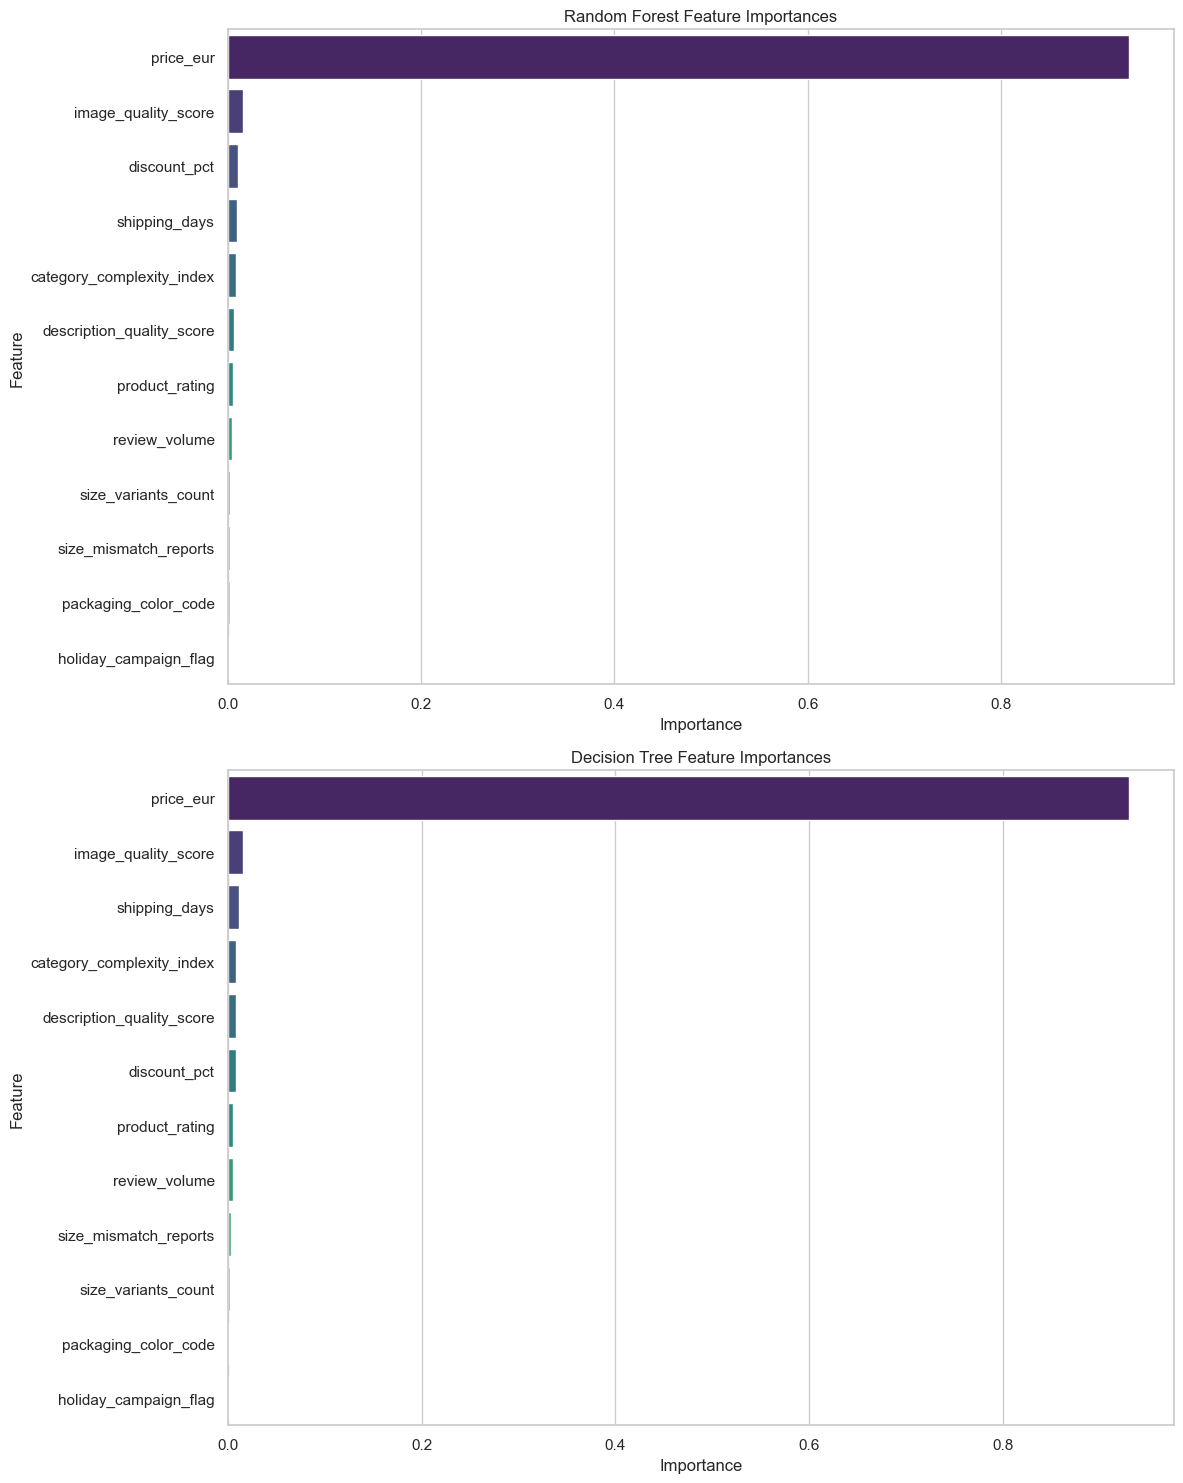

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(12, 15))

# Random Forest Feature Importances
importances = RF.feature_importances_
Feature_names = [col for col in X_train.columns]
feat_imp = pd.Series(importances, index=Feature_names).sort_values(ascending=False)

sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis", ax=axs[0])
axs[0].set_title("Random Forest Feature Importances")
axs[0].set_xlabel("Importance")
axs[0].set_ylabel("Feature")


# Decision Tree Feature Importances
importances = DT.feature_importances_
Feature_names = [col for col in X_train.columns]
feat_imp = pd.Series(importances, index=Feature_names).sort_values(ascending=False)

sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis", ax=axs[1])
axs[1].set_title("Decision Tree Feature Importances")
axs[1].set_xlabel("Importance")
axs[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()


After visualizing the feature importances for both the Random Forest and the Decision Tree, a very clear and consistent pattern emerges. 

**Key Observations:**
* **Price Dominance:** `Price` is by far the most important predictor of campaign return rates. This perfectly aligns with our earlier Exploratory Data Analysis, where `Price` showed the strongest correlation on the heatmap.
* **Secondary Drivers:** The `Image Quality Score` consistently ranks as the second most influential feature for both models.
* **Model Agreement:** Notably, both the Random Forest and the Decision Tree utilize the exact same features in the exact same order of importance. This unanimous agreement between the models gives us high confidence that we have identified the true primary drivers of return risk.

## 3.5 Nested cross-validation for the models we have so far

To wrap up this section, we should attempt nested cross-validation in order to get a more reliable estimate of the generalization performance of different models and obtain the distribution of the MSE (as opposed to a single value).

In [ ]:
from xgboost import XGBRegressor as XGBoost
from sklearn.ensemble import AdaBoostRegressor

outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_ridge = {"alpha": np.logspace(-2, 4, 20)}
param_lasso = {"alpha": np.logspace(-4, 1, 20)}
param_elasticnet = {"alpha": np.logspace(-4, 1, 20), "l1_ratio": np.linspace(0, 1, 20)}
param_randomforest = {"n_estimators": [50, 100], "max_depth": [None, 5, 10]}

param_xgboost = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2]
}

param_gradientboost = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 7], 
    "learning_rate": [0.01, 0.1, 0.2]
}

param_adaboost = {
    "n_estimators": [50, 100],
    "learning_rate": [0.01, 0.1, 0.2]
}

param_polynomials = {
    'poly__degree': [i for i in range(2, 5)] # This will test linear (1), quadratic (2), and cubic (3)
}

models = {
    'ridge': Ridge(),
    'lasso': Lasso(),
    'elasticnet': ElasticNet(),
    'randomforest': RandomForestRegressor(random_state=42),
    'xgboost': XGBoost(),
    'gradientboost': GradientBoostingRegressor(),
    'adaboost': AdaBoostRegressor(),
    'polynomial': Pipeline([
    ('poly', PolynomialFeatures(degree=4)), 
    ('scaler', StandardScaler()),
    ('linear', LinearRegression())
    ])
}


outer_scores = {name: [] for name in models.keys()}

X = train.drop(columns=['return_rate_pct'])
y = train['return_rate_pct']


for train_idx, test_idx in outer_cv.split(X):
    # Outer CV is used to make the main split
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Inner CV for tuning
    inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)
    grid_models = {
        'ridge': GridSearchCV(models['ridge'], param_ridge, cv=inner_cv),
        'lasso': GridSearchCV(models['lasso'], param_lasso, cv=inner_cv),
        'elasticnet': GridSearchCV(models['elasticnet'], param_elasticnet, cv=inner_cv),
        'randomforest': GridSearchCV(models['randomforest'], param_randomforest, cv=inner_cv),
        'xgboost': GridSearchCV(models['xgboost'], param_xgboost, cv=inner_cv),
        'gradientboost': GridSearchCV(models['gradientboost'], param_gradientboost, cv=inner_cv),
        'adaboost': GridSearchCV(models['adaboost'], param_adaboost, cv=inner_cv),
        'polynomial': GridSearchCV(models['polynomial'], param_polynomials, cv=inner_cv)
    }

    # See how now the fitting of the model + the searching of best hyperparameters looks like only one model
    for name, clf in grid_models.items():
        clf.fit(X_train, y_train)
        best_model = clf.best_estimator_
        mse = mean_squared_error(y_test, best_model.predict(X_test))
        outer_scores[name].append(mse)
    
sort = sorted(outer_scores.items(), key=lambda x: np.mean(x[1]))

for name, scores in sort:
    print(f"{name} | Avg MSE: {np.mean(scores):.4f} | Std: {np.std(scores):.4f}")



xgboost | Avg MSE: 25.5945 | Std: 1.6190
gradientboost | Avg MSE: 25.6247 | Std: 1.7805
randomforest | Avg MSE: 28.5712 | Std: 1.7836
adaboost | Avg MSE: 35.3302 | Std: 1.8831
polynomial | Avg MSE: 78.4649 | Std: 6.2559
ridge | Avg MSE: 120.9866 | Std: 6.1941
lasso | Avg MSE: 121.0654 | Std: 6.1451
elasticnet | Avg MSE: 121.1844 | Std: 6.1202


Note: The Ridge and Lasso MSE are reported when no polynomial features are used. We have not retested the linear model with powers of `price_eur`, since we will move towards a better idea in the next section. Notice that tree-based models perform better and their MSE has smaller variance.

## 3.6 Threshold

The biggest problem we have encountered so far is the bimodal distribution of the target. Given everything we have seen, it seems that establishing a threshold between the two target groups is a great next move.

Let us try to find a threshold to separate the two groups and employ different models depending on the category in which they fall.

We will try to split based on price_eur using a decision tree.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

X_threshold = train['price_eur']
y = train['return_rate_pct']

threshold_finder = DecisionTreeRegressor(max_depth=1, random_state=42)
threshold_finder.fit(X_threshold.values.reshape(-1, 1), y)

optimal_threshold = threshold_finder.tree_.threshold[0]
print(f"The optimal split point is: {optimal_threshold:.2f}")

The optimal split point is: 173.96


We're using DecisionTreeRegressor at depth 1 to make the sole most efficient cut of our data.

In [ ]:
df_low_price = train[train['price_eur'] <= optimal_threshold]
df_high_price = train[train['price_eur'] > optimal_threshold]

X_low = df_low_price.drop(columns=['return_rate_pct'])
y_low = df_low_price['return_rate_pct']

X_high = df_high_price.drop(columns=['return_rate_pct'])
y_high = df_high_price['return_rate_pct']

### Test on RandomForest

Separating the data into two data frames so we can train two models.

In [ ]:
# Test on RdForest

model_low_tier = RandomForestRegressor(n_estimators=100, random_state=42)
model_high_tier = RandomForestRegressor(n_estimators=100, random_state=42)

model_low_tier.fit(X_low, y_low)
print("Low_Done")
model_high_tier.fit(X_high, y_high)
print("High_Done")

Low_Done
High_Done


Let us train the two models on the categories of entries we established.

In [ ]:
# To hold onto the predictions
predictions = np.zeros(len(test))

# Sort of boolean list that serve as a filter
is_low = test['price_eur'] <= optimal_threshold #[True False True ...] True for low tier, False for high tier
is_high = test['price_eur'] > optimal_threshold #[True False True ...] True for high tier, False for low tier

# Low tier predictions
if is_low.any():
    # New list with index of the low tiers + their features
    X_new_low = test.loc[is_low, model_low_tier.feature_names_in_]

    # Predictions[is_low] targets the index of the low tiers from above
        # [True False True ...] => Index 1 and 3
    predictions[is_low] = model_low_tier.predict(X_new_low)
    
# High tier predictions
if is_high.any():
    # Same principle as low tier, but for high tier

    X_new_high = test.loc[is_high, model_high_tier.feature_names_in_]
    predictions[is_high] = model_high_tier.predict(X_new_high)

#print mse
final_mse = mean_squared_error(test['return_rate_pct'], predictions)
print(f"Final MSE on test set: {final_mse:.4f}")


Final MSE on test set: 25.4354


Next, we will again perform nested cross-validation. Let us setup the mechanism:

In [ ]:
from xgboost import XGBRegressor as XGBoost
from sklearn.ensemble import AdaBoostRegressor

outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_ridge = {"alpha": np.logspace(-2, 4, 20)}
param_lasso = {"alpha": np.logspace(-4, 1, 20)}
param_elasticnet = {"alpha": np.logspace(-4, 1, 20), "l1_ratio": np.linspace(0, 1, 20)}
param_randomforest = {"n_estimators": [50, 100], "max_depth": [None, 5, 10]}

param_xgboost = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2]
}

param_gradientboost = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 7], 
    "learning_rate": [0.01, 0.1, 0.2]
}

param_adaboost = {
    "n_estimators": [50, 100],
    "learning_rate": [0.01, 0.1, 0.2]
}

param_polynomials = {
    'poly__degree': [i for i in range(2, 5)] # This will test linear (1), quadratic (2), and cubic (3)
}

models = {
    'ridge': Ridge(),
    'lasso': Lasso(),
    'elasticnet': ElasticNet(),
    'randomforest': RandomForestRegressor(random_state=42),
    'xgboost': XGBoost(),
    'gradientboost': GradientBoostingRegressor(),
    'adaboost': AdaBoostRegressor(),
    'polynomial': Pipeline([
    ('poly', PolynomialFeatures(degree=4)), 
    ('scaler', StandardScaler()),
    ('linear', LinearRegression())
    ])
}

param_grids = {
    'ridge': param_ridge,
    'lasso': param_lasso,
    'elasticnet': param_elasticnet,
    'randomforest': param_randomforest,
    'xgboost': param_xgboost,
    'gradientboost': param_gradientboost,
    'adaboost': param_adaboost,
    'polynomial': param_polynomials
}


X = train.drop(columns=['return_rate_pct'])
y = train['return_rate_pct']

Here is the result of nested cross-validation when one model is chosen, but its parameters are learned differently for the two categories of entries (specialized in the low price range and the high price range).

In [ ]:
outer_scores = {name: [] for name in models.keys()}
optimal_threshold = threshold_finder.tree_.threshold[0]

for train_idx, val_idx in outer_cv.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    train_low_mask = X_train['price_eur'] <= optimal_threshold
    val_low_mask = X_val['price_eur'] <= optimal_threshold
    
    X_train_low, y_train_low = X_train[train_low_mask], y_train[train_low_mask]
    X_train_high, y_train_high = X_train[~train_low_mask], y_train[~train_low_mask]
    
    X_val_low, y_val_low = X_val[val_low_mask], y_val[val_low_mask]
    X_val_high, y_val_high = X_val[~val_low_mask], y_val[~val_low_mask]

    inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)
    for name, model in models.items():
        # Tune on Low segment
        grid_low = GridSearchCV(model, param_grids[name], cv=inner_cv)
        grid_low.fit(X_train_low, y_train_low)
        
        # Tune on High segment
        grid_high = GridSearchCV(model, param_grids[name], cv=inner_cv)
        grid_high.fit(X_train_high, y_train_high)
        
        preds = np.zeros(len(X_val))
        
        # Predict using tuned models
        if len(X_val_low) > 0:
            preds[val_low_mask] = grid_low.best_estimator_.predict(X_val_low)
        if len(X_val_high) > 0:
            preds[~val_low_mask] = grid_high.best_estimator_.predict(X_val_high)
            
        fold_mse = mean_squared_error(y_val, preds)
        outer_scores[name].append(fold_mse)
    sort = sorted(outer_scores.items(), key=lambda x: np.mean(x[1]))

for name, scores in sort:
    print(f"{name} | Avg MSE: {np.mean(scores):.4f} | Std: {np.std(scores):.4f}")



xgboost | Avg MSE: 26.1514 | Std: 1.7260
gradientboost | Avg MSE: 26.4157 | Std: 1.9636
randomforest | Avg MSE: 28.3466 | Std: 1.8956
polynomial | Avg MSE: 29.2318 | Std: 2.3206
adaboost | Avg MSE: 31.9129 | Std: 2.0334
ridge | Avg MSE: 57.1191 | Std: 1.8456
lasso | Avg MSE: 57.1578 | Std: 1.6153
elasticnet | Avg MSE: 57.3180 | Std: 1.9145


Unfortunately, the threshold separation seems to make the predictions still slightly worse.

## Different Model Based on the Threshold

We performed the nested CV using the same model for both high and low prices (although trained differently on the two price ranges). <br>
Instead, let us try to combine two different models: one acting on the low price range, one on the high price range.

In [ ]:
low_segment_results = {name: [] for name in models.keys()}

print("--- Evaluating Models for the LOW TIER ---")

for train_idx, val_idx in outer_cv.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    train_low_mask = X_train['price_eur'] <= optimal_threshold
    val_low_mask = X_val['price_eur'] <= optimal_threshold
    
    X_train_low, y_train_low = X_train[train_low_mask], y_train[train_low_mask]
    X_val_low, y_val_low = X_val[val_low_mask], y_val[val_low_mask]
    
    if len(X_train_low) < 5 or len(X_val_low) == 0: #Skip if not enough
        continue

    inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)
    
    for name, model in models.items():
        grid = GridSearchCV(model, param_grids[name], cv=inner_cv, scoring='neg_mean_squared_error')
        grid.fit(X_train_low, y_train_low)
        
        preds = grid.best_estimator_.predict(X_val_low)
        mse = mean_squared_error(y_val_low, preds)
        low_segment_results[name].append(mse)
        
sort = sorted(low_segment_results.items(), key=lambda x: np.mean(x[1]))

print("\nResults for Low Tier:")
for name, scores in sort:
    print(f"{name.upper()} | Avg MSE: {np.mean(scores):.4f} | Std: {np.std(scores):.4f}")

--- Evaluating Models for the LOW TIER ---

Results for Low Tier:
POLYNOMIAL | Avg MSE: 11.1262 | Std: 1.3777
GRADIENTBOOST | Avg MSE: 12.9298 | Std: 1.2238
XGBOOST | Avg MSE: 12.9585 | Std: 1.1199
RANDOMFOREST | Avg MSE: 16.9490 | Std: 0.5331
ADABOOST | Avg MSE: 22.1379 | Std: 1.4454
LASSO | Avg MSE: 47.5869 | Std: 2.8103
RIDGE | Avg MSE: 47.5927 | Std: 2.8747
ELASTICNET | Avg MSE: 47.6357 | Std: 2.9108


The best model for the low prices seems to be polynomial regression, achieving a MSE of 11.12.

In [ ]:
high_segment_results = {name: [] for name in models.keys()}

print("--- Evaluating Models for the HIGH TIER ---")

for train_idx, val_idx in outer_cv.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    train_high_mask = X_train['price_eur'] > optimal_threshold
    val_high_mask = X_val['price_eur'] > optimal_threshold
    
    X_train_high, y_train_high = X_train[train_high_mask], y_train[train_high_mask]
    X_val_high, y_val_high = X_val[val_high_mask], y_val[val_high_mask]
    
    if len(X_train_high) < 5 or len(X_val_high) == 0:
        continue

    inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)
    
    for name, model in models.items():
        grid = GridSearchCV(model, param_grids[name], cv=inner_cv, scoring='neg_mean_squared_error')
        grid.fit(X_train_high, y_train_high)
        
        preds = grid.best_estimator_.predict(X_val_high)
        mse = mean_squared_error(y_val_high, preds)
        high_segment_results[name].append(mse)

sort = sorted(high_segment_results.items(), key=lambda x: np.mean(x[1]))

print("\nResults for High Tier:")
for name, scores in sort:
    print(f"{name.upper()} | Avg MSE: {np.mean(scores):.4f} | Std: {np.std(scores):.4f}")

--- Evaluating Models for the HIGH TIER ---

Results for High Tier:
RANDOMFOREST | Avg MSE: 46.1363 | Std: 3.8940
ADABOOST | Avg MSE: 46.3656 | Std: 6.1758
XGBOOST | Avg MSE: 46.8142 | Std: 3.7720
GRADIENTBOOST | Avg MSE: 47.4736 | Std: 3.8902
POLYNOMIAL | Avg MSE: 57.8010 | Std: 7.4382
LASSO | Avg MSE: 72.2456 | Std: 2.5822
ELASTICNET | Avg MSE: 72.4615 | Std: 2.7451
RIDGE | Avg MSE: 72.5465 | Std: 3.1780


The best model for the high prices seems to be Random Forest, achieving a MSE of 46.13.

We'll use a function to test different pairs of models with Nested CV to see which performs the best.

In [ ]:
def Bimodal_model_test(X, y, low_model, high_model):
    bimodal_mse_scores = []

    for train_idx, val_idx in outer_cv.split(X,y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        train_low_mask = X_train['price_eur'] <= optimal_threshold
        val_low_mask = X_val['price_eur'] <= optimal_threshold

        preds = np.zeros(len(X_val))

        #low
        if train_low_mask.sum() > 5:
            grid_low = GridSearchCV(models[low_model], param_grids[low_model], cv=3)
            grid_low.fit(X_train[train_low_mask], y_train[train_low_mask])
            
            if val_low_mask.any():
                preds[val_low_mask] = grid_low.best_estimator_.predict(X_val[val_low_mask])
        
        #high
        if (~train_low_mask).sum() > 5:
            grid_high = GridSearchCV(models[high_model], param_grids[high_model], cv=3)
            grid_high.fit(X_train[~train_low_mask], y_train[~train_low_mask])
            
            if (~val_low_mask).any():
                preds[~val_low_mask] = grid_high.best_estimator_.predict(X_val[~val_low_mask])
                   
        fold_mse = mean_squared_error(y_val, preds)
        bimodal_mse_scores.append(fold_mse)

    print(f"Bimodal Strategy ({low_model}-Low / {high_model}-High) MSE: {np.mean(bimodal_mse_scores):.4f} (± {np.std(bimodal_mse_scores):.4f})")

## a) Bimodal Model: Polynomial-Low / RandomForest-High

In [ ]:
Bimodal_model_test(X,y,'polynomial', "randomforest")

Bimodal Strategy (polynomial-Low / randomforest-High) MSE: 24.7528 (± 2.2737)


## b) Bimodal Model: GradiengBoost-Low / RandomForest-High

In [ ]:
Bimodal_model_test(X,y,'gradientboost', "randomforest")

Bimodal Strategy (gradientboost-Low / randomforest-High) MSE: 25.6879 (± 2.1355)


## c) Bimodal Model: XGBoost-Low / RandomForest-High


In [ ]:
Bimodal_model_test(X,y,'xgboost', "randomforest")

Bimodal Strategy (xgboost-Low / randomforest-High) MSE: 25.8596 (± 2.2648)


Both the bimodal using GradientBoost and XGBoost are outperformed by the polynomial regression. \
As the performance is worse there is no need to use them; however it was still interesting to look at their performance.

# 4. Validation and Optimization (Nested Cross-Validation):

The Bimodal Model using Polynomial Regression for lower prices and Random Forest for higher prices has the best overall performance.<br>
Focusing on finding a threshold seems to have been the good choice in this situation. Let us define a class for it:

## 4.1. Hyperparameter choice and CV

In [ ]:
from sklearn.base import BaseEstimator, RegressorMixin #Have to have this for the CV apparently

class BimodalPolyRfRegressor(BaseEstimator, RegressorMixin): #BaseEstimator & RegressorMixin for the CV's 
    def __init__(self, threshold=173.96, threshold_feature='price_eur', random_state=42):
        self.threshold = threshold
        self.threshold_feature = threshold_feature
        self.random_state = random_state
        
        self.grid_low_ = None
        self.grid_high_ = None

    def fit(self, X, y):
        #Models
        model_poly = Pipeline([
            ('poly', PolynomialFeatures()), 
            ('scaler', StandardScaler()),
            ('linear', LinearRegression())
        ])
        poly_params = {
            'poly__degree': list(range(0, 6))
        }

        model_rf = RandomForestRegressor(random_state=self.random_state)
        rf_params = {
            "n_estimators": [50, 100], 
            "max_depth": [None, 5, 10]
        }

        #Grid
        self.grid_low_ = GridSearchCV(model_poly, poly_params, cv=3)
        self.grid_high_ = GridSearchCV(model_rf, rf_params, cv=3)

        #Threshold
        low_mask = X[self.threshold_feature] <= self.threshold


        #Fitting
        if low_mask.any():
            self.grid_low_.fit(X[low_mask], y[low_mask])
            
        if (~low_mask).any():
            self.grid_high_.fit(X[~low_mask], y[~low_mask])

        return self 

    def predict(self, X):
        predictions = np.zeros(len(X))
        
        #Threshold
        low_mask = X[self.threshold_feature] <= self.threshold

        # Predict
        if low_mask.any():
            predictions[low_mask] = self.grid_low_.predict(X[low_mask])
            
        if (~low_mask).any():
            predictions[~low_mask] = self.grid_high_.predict(X[~low_mask])

        return predictions

## Prediction using our model

Now that we have a model that seems very good, let us try to use it.

#### Setup (reinitializing variables)

In [ ]:
X_train = train.drop(columns=['return_rate_pct'])
y_train = train['return_rate_pct']
X_test = test.drop(columns=['return_rate_pct'])
y_test = test['return_rate_pct']

model = BimodalPolyRfRegressor()
model.fit(X_train, y_train)

y_train_prediction = model.predict(X_train)
y_test_prediction = model.predict(X_test)

## 5. Error Analysis and Conclusion:

Before making a final model choice, let us take a look at the residuals when using our best model so far:

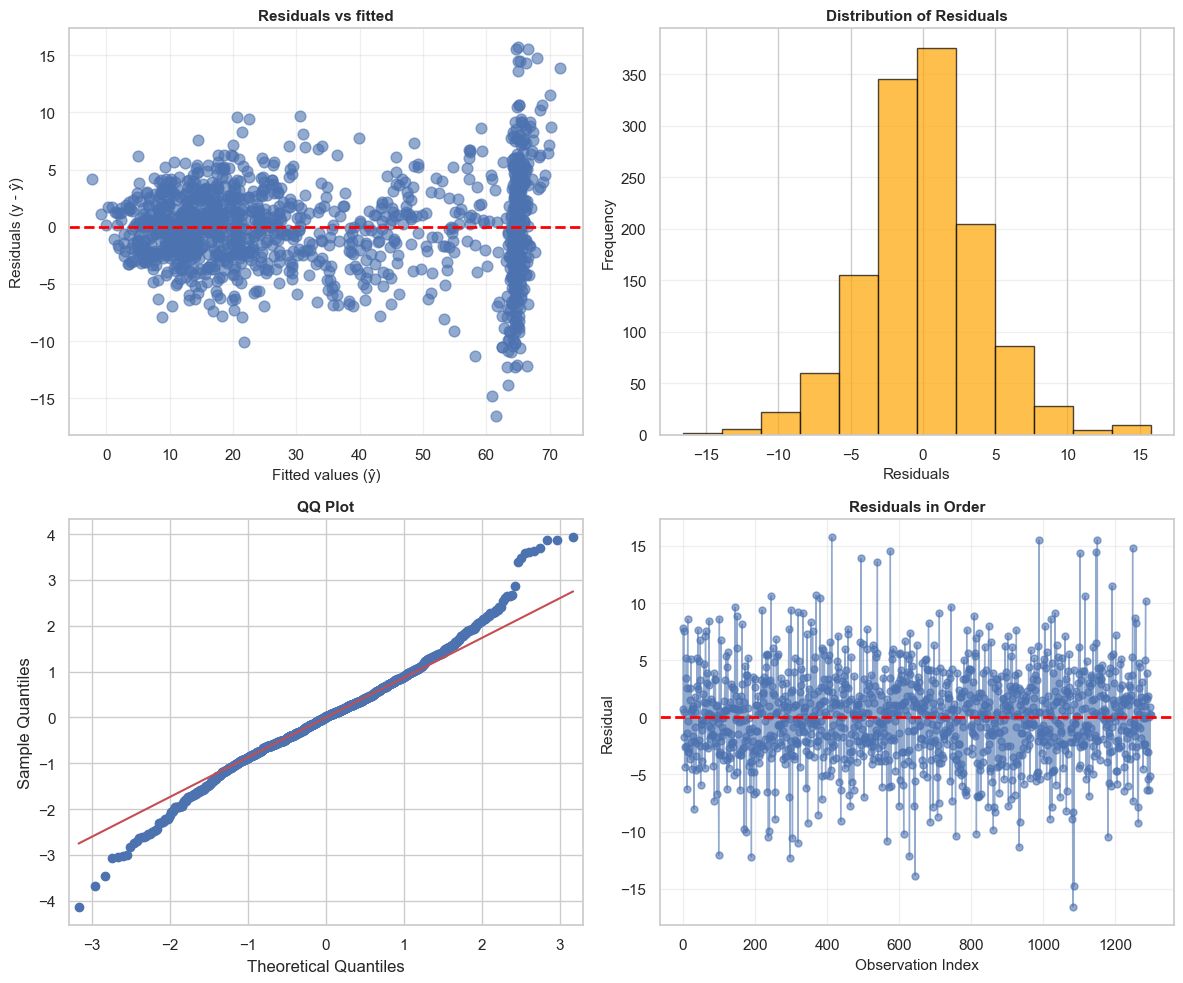


Comparison of Training vs Test Residuals:
Training residuals mean: -0.006853, std: 4.0114
Test residuals mean: -0.049187, std: 4.6844


In [ ]:
plot_residual_summaries(None, y_train_prediction, y_test_prediction)

#  !!!! do not forget to repeat MSE value, here goes final analysis of residuals + final model choice with business perspective + DO A FINAL RUN OF NOTEBOOK, ENSURE IT WORKS FROM START TO FINISH